### Visualization
To evaluate the trained inverse PINN visually, we examine both the training dynamics and the resulting option-price surface.

In [40]:
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from inverse_pinn_model import InversePINN

VIS_SEED = 42

random.seed(VIS_SEED)
np.random.seed(VIS_SEED)
torch.manual_seed(VIS_SEED)

device = torch.device("cpu")
dtype = torch.float64

In [41]:
# Reload the updated inverse_pinn_model.py

import importlib
import inverse_pinn_model

# Force Python to read the updated .py file again
importlib.reload(inverse_pinn_model)

# Re-import the updated class
InversePINN = inverse_pinn_model.InversePINN

In [42]:
checkpoint_vis = torch.load(
    "european_visualization_checkpoint.pt",
    weights_only=False
)

history = checkpoint_vis["history"]

t_min = checkpoint_vis["t_min"]
t_max = checkpoint_vis["t_max"]

S_min = checkpoint_vis["S_min"]
S_max = checkpoint_vis["S_max"]

K = checkpoint_vis["K"]
T = checkpoint_vis["T"]

r_true = checkpoint_vis["r_true"]
sigma_true = checkpoint_vis["sigma_true"]

hidden_width = checkpoint_vis["hidden_width"]
hidden_layers = checkpoint_vis["hidden_layers"]

In [43]:
model = InversePINN(
    t_min=t_min,
    t_max=t_max,
    S_min=S_min,
    S_max=S_max,
    hidden_width=hidden_width,
    hidden_layers=hidden_layers,
    r_initial=0.10,
    sigma_initial=0.40
).to(
    device=device,
    dtype=dtype
)

model.load_state_dict(
    checkpoint_vis["model_state_dict"]
)

model.eval()

InversePINN(
  (model): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): Tanh()
    (6): Linear(in_features=64, out_features=64, bias=True)
    (7): Tanh()
    (8): Linear(in_features=64, out_features=1, bias=True)
  )
)

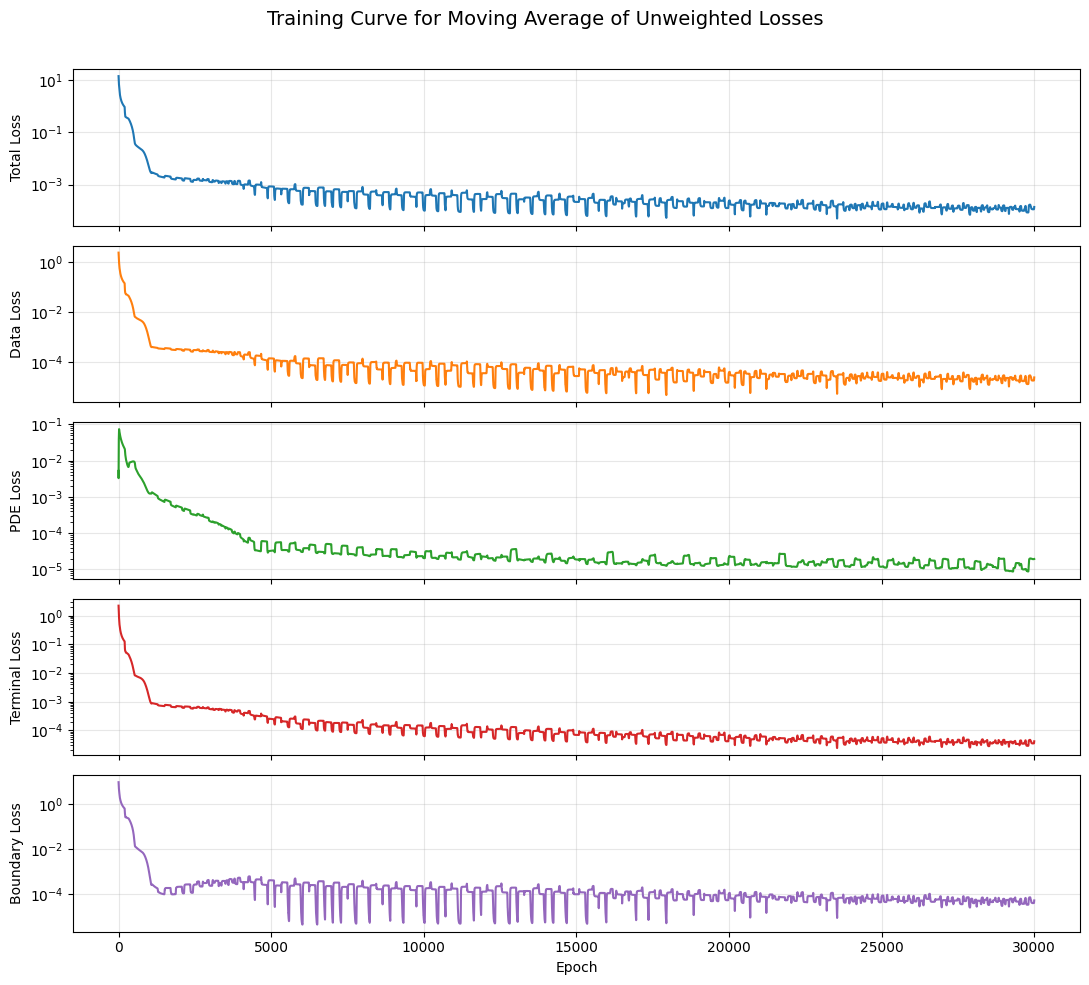

In [44]:
# Unweighted training loss vs. epoch

# Number of epochs in the first training run
n_epochs = 30000

epochs = np.array(
    history["epoch"][:n_epochs]
)

data_loss_plot = np.array(
    history["data_loss"][:n_epochs]
)

pde_loss_plot = np.array(
    history["pde_loss"][:n_epochs]
)

terminal_loss_plot = np.array(
    history["terminal_loss"][:n_epochs]
)

boundary_loss_plot = np.array(
    history["boundary_loss"][:n_epochs]
)



# Unweighted total loss
# Lambda weights are NOT included.

total_loss_plot = (
    data_loss_plot
    + pde_loss_plot
    + terminal_loss_plot
    + boundary_loss_plot
)

# Moving average
# PINN losses can oscillate during training.

window = 200


def moving_average(values, window):
    return (
        pd.Series(values)
        .rolling(
            window=window,
            min_periods=1
        )
        .mean()
        .to_numpy()
    )


total_ma = moving_average(
    total_loss_plot,
    window
)

data_ma = moving_average(
    data_loss_plot,
    window
)

pde_ma = moving_average(
    pde_loss_plot,
    window
)

terminal_ma = moving_average(
    terminal_loss_plot,
    window
)

boundary_ma = moving_average(
    boundary_loss_plot,
    window
)


# Plot each loss component in a separate panel

fig, axes = plt.subplots(
    5,
    1,
    figsize=(11, 10),
    sharex=True
)


# Total loss
axes[0].plot(
    epochs,
    total_ma,
    color="tab:blue"
)
axes[0].set_ylabel("Total Loss")
axes[0].set_yscale("log")
axes[0].grid(True, alpha=0.3)


# Data loss
axes[1].plot(
    epochs,
    data_ma,
    color="tab:orange"
)
axes[1].set_ylabel("Data Loss")
axes[1].set_yscale("log")
axes[1].grid(True, alpha=0.3)


# PDE loss
axes[2].plot(
    epochs,
    pde_ma,
    color="tab:green"
)
axes[2].set_ylabel("PDE Loss")
axes[2].set_yscale("log")
axes[2].grid(True, alpha=0.3)


# Terminal loss
axes[3].plot(
    epochs,
    terminal_ma,
    color="tab:red"
)
axes[3].set_ylabel("Terminal Loss")
axes[3].set_yscale("log")
axes[3].grid(True, alpha=0.3)


# Boundary loss
axes[4].plot(
    epochs,
    boundary_ma,
    color="tab:purple"
)
axes[4].set_ylabel("Boundary Loss")
axes[4].set_yscale("log")
axes[4].set_xlabel("Epoch")
axes[4].grid(True, alpha=0.3)


fig.suptitle(
    "Training Curve for Moving Average of Unweighted Losses",
    fontsize=14
)

plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)

plt.show()

In [45]:
# analytical solution vs. PINN prediction
# Training data: 2000
# Testing/visualization: 100*100

# construct a uniform 100 * 100 grid
N_test = 100

t_test_1d = torch.linspace(
    t_min,
    t_max,
    N_test,
    dtype=dtype,
    device = device
)

S_test_1d = torch.linspace(
    S_min,
    S_max,
    N_test,
    dtype=dtype,
    device=device
)

# Convert the two one-dimensional grids into a 2D mesh
t_mesh, S_mesh = torch.meshgrid(
    t_test_1d,
    S_test_1d,
    indexing="ij"
)

# Flatten the mesh into 10,000 (t,S) pairs
t_test = t_mesh.reshape(-1,1)
S_test = S_mesh.reshape(-1,1)

print(
    "Number of test points:",
    t_test.shape[0]
)

Number of test points: 10000


In [46]:
# analytical BS solution

def black_scholes_call(
        t,
        S,
        K,
        T,
        r,
        sigma
):

    #time remaining until maturity
    tau = T -t
    eps = 1e-12

    tau_safe = torch.clamp(
        tau,
        min=eps
    )
    S_safe = torch.clamp(
        S,
        min=eps
    )

     # Black-Scholes d1 and d2
    d1 = (
        torch.log(S_safe / K)
        + (
            r
            + 0.5 * sigma**2
        ) * tau_safe
    ) / (
        sigma * torch.sqrt(tau_safe)
    )

    d2 = (
        d1
        - sigma * torch.sqrt(tau_safe)
    )


    # Standard normal CDF
    N_d1 = 0.5 * (
        1.0
        + torch.erf(
            d1 / np.sqrt(2.0)
        )
    )

    N_d2 = 0.5 * (
        1.0
        + torch.erf(
            d2 / np.sqrt(2.0)
        )
    )


    # European call price
    V = (
        S_safe * N_d1
        - K
        * torch.exp(
            -r * tau_safe
        )
        * N_d2
    )


    # At maturity:
    # V(T,S) = max(S-K,0)
    payoff = torch.relu(
        S - K
    )

    V = torch.where(
        tau <= eps,
        payoff,
        V
    )


    # At S = 0:
    # V = 0
    V = torch.where(
        S <= eps,
        torch.zeros_like(V),
        V
    )

    return V


In [47]:
# True para used to generate the synthetic observations
r_true = 0.05
sigma_true = 0.20
with torch.no_grad():

    V_true = black_scholes_call(
        t=t_test,
        S=S_test,
        K=K,
        T=T,
        r=r_true,
        sigma=sigma_true
    )

In [48]:
# PINN prediction on the same uniform grid 
model.eval()
with torch.no_grad():

    # The PINN predicts normalized option price:
    # u = V / K
    u_prediction = model(
        t_test,
        S_test
    )

    # Convert normalized price back to actual option price
    V_prediction = (
        K * u_prediction
    )

In [49]:
# Test MSE on the 100 * 100 uniform grid

test_mse = torch.mean(
    (
    V_true - V_prediction
) ** 2
).item()

print(
    f"Uniform-grid test MSE: {test_mse:.8e}"
)

Uniform-grid test MSE: 2.31539194e-01


In [50]:
# Reshape predictions back to 100 * 100 surfaces
t_surface = (
    t_mesh.cpu().numpy()
)

S_surface = (
    S_mesh.cpu().numpy()
)
V_true_surface = (
    V_true
    .reshape(
        N_test,
        N_test
    )
    .cpu()
    .numpy()
)
V_prediction_surface = (
    V_prediction
    .reshape(
        N_test,
        N_test
    )
    .cpu()
    .numpy()
)

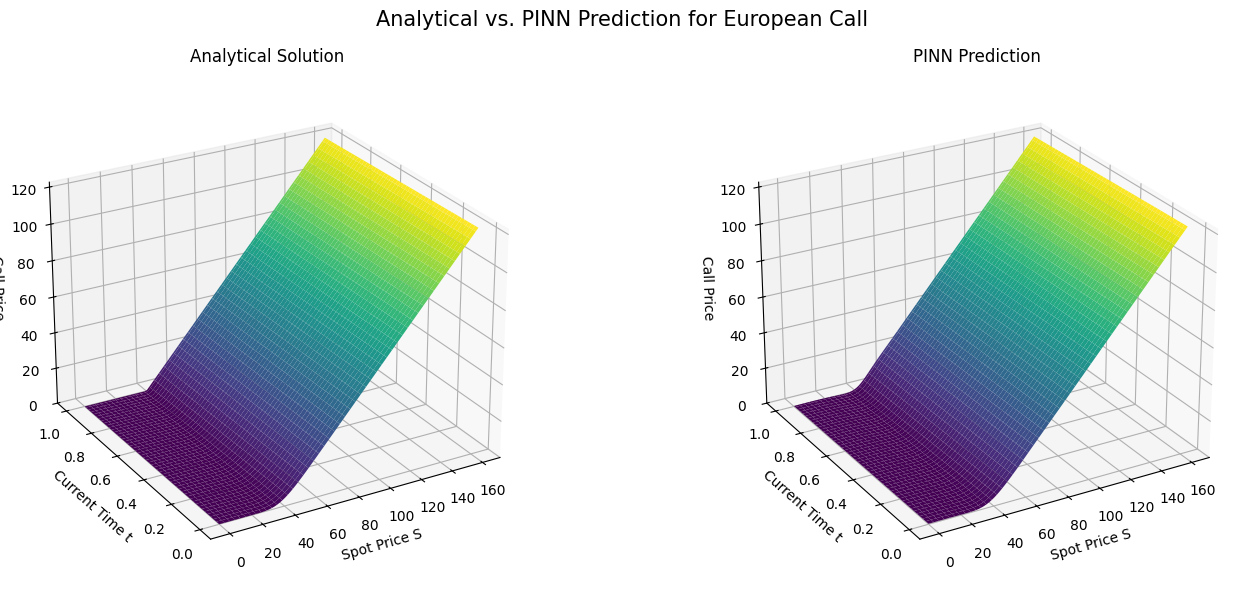

In [51]:
# Plot Analytical vs. PINN surfaces

fig = plt.figure(
    figsize=(15, 6)
)


# Analytical solution

ax1 = fig.add_subplot(
    1,
    2,
    1,
    projection="3d"
)

ax1.plot_surface(
    S_surface,
    t_surface,
    V_true_surface,
    cmap="viridis",
    edgecolor="none"
)

ax1.set_title(
    "Analytical Solution"
)

ax1.set_xlabel(
    "Spot Price S"
)

ax1.set_ylabel(
    "Current Time t"
)

ax1.set_zlabel(
    "Call Price"
)


# PINN prediction

ax2 = fig.add_subplot(
    1,
    2,
    2,
    projection="3d"
)

ax2.plot_surface(
    S_surface,
    t_surface,
    V_prediction_surface,
    cmap="viridis",
    edgecolor="none"
)

ax2.set_title(
    "PINN Prediction"
)

ax2.set_xlabel(
    "Spot Price S"
)

ax2.set_ylabel(
    "Current Time t"
)

ax2.set_zlabel(
    "Call Price"
)


# Use the same z-axis range

z_min = min(
    V_true_surface.min(),
    V_prediction_surface.min()
)

z_max = max(
    V_true_surface.max(),
    V_prediction_surface.max()
)

ax1.set_zlim(
    z_min,
    z_max
)

ax2.set_zlim(
    z_min,
    z_max
)


# Use the same camera angle
ax1.view_init(
    elev=25,
    azim=-120
)

ax2.view_init(
    elev=25,
    azim=-120
)


fig.suptitle(
    "Analytical vs. PINN Prediction for European Call",
    fontsize=15
)

plt.tight_layout()

plt.show()

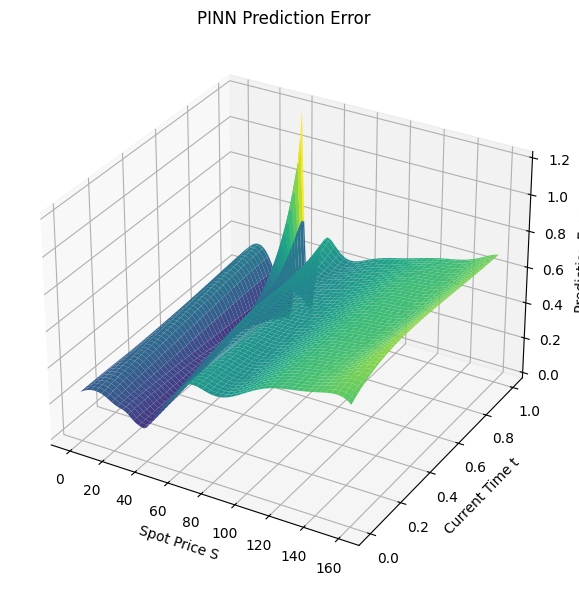

In [52]:
# Error surface
error_surface = (
    (V_prediction - V_true)
    .reshape(N_test, N_test)
    .cpu()
    .numpy()
)

fig = plt.figure(
    figsize=(8, 6)
)

ax = fig.add_subplot(
    111,
    projection="3d"
)

ax.plot_surface(
    S_surface,
    t_surface,
    error_surface,
    cmap="viridis",
    edgecolor="none"
)

ax.set_xlabel("Spot Price S")
ax.set_ylabel("Current Time t")
ax.set_zlabel("Prediction Error")

ax.set_title(
    "PINN Prediction Error"
)

plt.tight_layout()
plt.show()